# 软测量
## 定义
#### 就是通过软件代替硬件传感器（昂贵的仪器）来测量

模型的 R² 评分: 0.8592


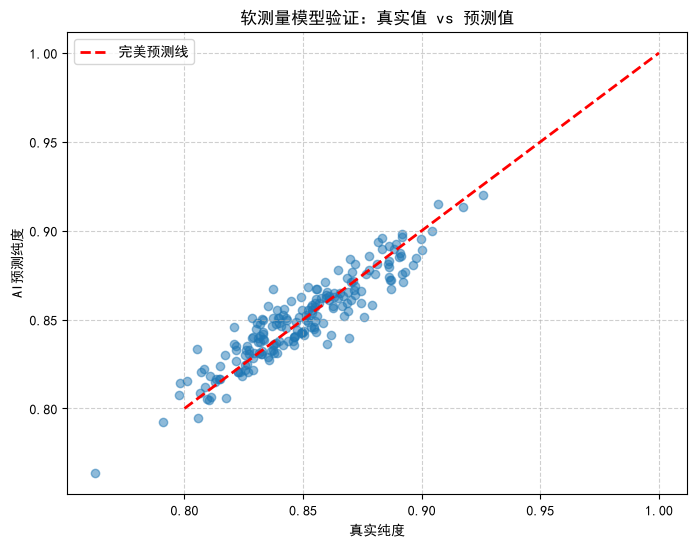

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
#设定中文
plt.rcParams['font.sans-serif'] = ['SimHei']  # 设置中文字体
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题


# 1. 模拟 1000 组 DCS 历史数据（假设真实物理规律存在，但带有测量噪声）
np.random.seed(42)
n_samples = 1000
temperature = np.random.normal(80, 5, n_samples)   # 塔顶温度，均值80，标准差5
pressure = np.random.normal(0.5, 0.05, n_samples)  # 塔顶压力
# 假设真实纯度规律是：纯度 = 1.2 - 0.005*T + 0.1*P + 噪声
purity = 1.2 - 0.005 * temperature + 0.1 * pressure + np.random.normal(0, 0.01, n_samples)

df = pd.DataFrame({'温度': temperature, '压力': pressure, '真实纯度': purity})

# 2. 准备特征(X)和目标(y)
X = df[['温度', '压力']]  # 易测变量（特征）
y = df['真实纯度']        # 难测变量（目标）

# 3. 划分训练集和测试集 (80%训练，20%测试)
# 提示：train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. 训练模型
# 提示：model = LinearRegression()
model = LinearRegression()
model.fit(X_train, y_train) # 让模型学习

# 5. 预测与评估
# 提示：y_pred = model.predict(X_test)
y_pred = model.predict(X_test)

# 计算 R² (决定系数，越接近 1 越好，表示模型能解释的数据变异程度)
r2 = r2_score(y_test, y_pred)
print(f"模型的 R² 评分: {r2:.4f}")

# 6. 画图：看看预测值和真实值到底有多贴合
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='tab:blue')
# 画一条 y=x 的完美预测线
plt.plot([0.8, 1.0], [0.8, 1.0], 'r--', lw=2, label='完美预测线')
plt.xlabel('真实纯度')
plt.ylabel('AI预测纯度')
plt.title('软测量模型验证：真实值 vs 预测值')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 软测量 Demo 复习笔记

> 笔记对象：`chemical_code/Soft_Sensor.ipynb` 的第 2 个代码单元格（`id=2b988cf4`）。  
> 写法约定：下文 `Lxx` 指**该代码单元格内部**从 1 开始的行号，不是 `.ipynb` JSON 文件的行号。  
> 说明：原 notebook 没有给出具体“卡住的地方”，以下按初学者的通用难点展开；涉及真实工业数据的部分标注为“假设/待确认”。

## 0. 运行环境与结论速览

| 项目 | 内容 |
|---|---|
| 语言 | Python 3.11.17（`chem_eng` 环境） |
| 主要库 | pandas 3.0.6、numpy 2.4.6、scikit-learn 1.9.1、matplotlib 3.11.2 |
| 运行方式 | Jupyter Notebook / VS Code，逐单元格执行 |
| 数据规模 | 1000 行 × 3 列；训练 800 行，测试 200 行 |
| 本次实测 | R² = 0.8592；MAE = 0.0079（代码已导入 MAE，但未调用） |
| 拟合结果 | 纯度 ≈ 1.1958 − 0.004942×温度 + 0.099609×压力 |
| 重要提醒 | R² 不是“准确率 85.92%”；它是测试集上被模型解释的方差比例 |

**假设/待确认**

- 假设 notebook 实际使用的 kernel 是 `chem_eng`；若 VS Code 选的是别的 Python，库版本和输出可能有差异。
- 假设“温度 80、压力 0.5、纯度 0.85”是演示用单位；代码没有写单位，真实 DCS 数据必须确认单位与量程。
- 假设纯度是 0～1 的质量分数/摩尔分数；代码没有做 0～1 裁剪，极端样本可能越界。

# 一、一句话总览

- **这个 demo 解决什么问题**：用容易测量的塔顶温度、压力，训练一个线性软测量模型，去预测难在线测量（或测量滞后）的产品纯度。
- **核心输入**：1000 组模拟 DCS 数据中的 `温度`、`压力` 两列特征；训练时还需要 `真实纯度` 作为标签。
- **预期输出**：
  1. 测试集预测值 `y_pred`；
  2. 测试集 R²（本例 0.8592）和一张“真实纯度 vs 预测纯度”散点图；
  3. 一个可复用的 `LinearRegression` 模型（`model.coef_`、`model.intercept_`）。
- **一句话概括核心机制**：先用已知的线性物理规律“造数据”，再让多元线性回归从 800 个样本中估计 `纯度 = b0 + b1×温度 + b2×压力` 的系数，最后在 200 个没见过的样本上验证。
- **适合复习的关键词**：软测量、辅助变量、主导变量、多元线性回归、训练集/测试集、R²、MAE、过拟合、外推、数据泄漏、随机种子。

> 一句话记忆：**软测量 = 用“好测的 X”学一个模型，去替代“难测的 y”。**

# 二、功能与输入输出（对应第 1 点）

## 功能拆解

1. **准备工具**（L1–L9）：导入 pandas、numpy、matplotlib、sklearn；设置中文字体和负号显示。
2. **造一份“带噪声的历史数据”**（L12–L20）：生成 1000 个温度、压力样本，再按已知线性公式生成纯度，并叠加测量噪声。
3. **区分特征与标签**（L22–L24）：`X` 放易测变量（温度、压力），`y` 放难测变量（真实纯度）。
4. **划分训练集/测试集**（L26–L28）：80% 训练、20% 测试，固定随机种子保证可复现。
5. **训练线性模型**（L30–L33）：用训练集拟合 `LinearRegression`，学习截距和两个系数。
6. **预测、评估、可视化**（L35–L53）：在测试集上预测，计算 R²，画散点图和 `y=x` 完美预测线。

> 注意：这个 demo 的重点不是“调参”，而是走通软测量的最小闭环：**数据 → 特征/标签 → 划分 → 训练 → 评估 → 解释**。

## 输入表

| 输入项 | 类型/格式 | 含义 | 是否必需 | 示例 | 约束/说明 |
|---|---|---|---|---|---|
| `temperature` | `numpy.ndarray`，shape `(1000,)`，float64 | 塔顶温度，辅助变量 | 是 | 80.2 | 代码假设服从 N(80, 5²)；真实数据需确认单位、量程、采样周期 |
| `pressure` | `numpy.ndarray`，shape `(1000,)`，float64 | 塔顶压力，辅助变量 | 是 | 0.51 | 代码假设服从 N(0.5, 0.05²)；理论上可能生成负值，但概率极低 |
| `purity` | `numpy.ndarray`，shape `(1000,)`，float64 | 产品纯度，主导变量/标签 | 训练时必需，预测时不需要 | 0.85 | 由公式加噪声生成；若为质量分数应落在 0～1，但代码未裁剪 |
| `n_samples` | `int` | 样本数 | 是 | 1000 | 必须为正整数；太小会导致划分失败或评估不稳定 |
| `test_size` | `float` | 测试集比例 | 否，默认 0.25 | 0.2 | 必须在 (0, 1) 内；本例 1000×0.2=200 |
| `random_state` | `int` | 随机划分的种子 | 否 | 42 | 只控制“怎么分”，不控制模型拟合 |
| `X` | `pandas.DataFrame`，shape `(1000, 2)` | 特征矩阵，列顺序为 `温度, 压力` | 是 | 两列数值 | 必须是二维；列名要和训练时一致 |
| `y` | `pandas.Series`，shape `(1000,)` | 目标向量 | 训练时是 | 0.85 | 长度必须与 X 行数一致；不能含 NaN |

**输入从哪来？**

- 本 demo：`np.random.normal` 模拟，不读文件、不连 DCS。
- 真实项目：通常来自 DCS 历史库/CSV/数据库；需要额外处理时间戳对齐、缺失值、异常值、单位换算、实验室化验滞后。以上均为**假设/待确认**，代码没有实现。

## 输出表

| 输出项 | 类型/格式 | 含义 | 示例 | 成功标准 |
|---|---|---|---|---|
| `y_pred` | `numpy.ndarray`，shape `(200,)` | 测试集 200 个样本的预测纯度 | 0.8502 | shape 与 `y_test` 一致；数值在合理范围内 |
| `r2` | `numpy.float64` | 测试集决定系数 R² | 0.8592 | 越接近 1 越好；但要看任务和基线，不能只看这一个数 |
| `model.coef_` | `numpy.ndarray`，shape `(2,)` | 温度、压力每变化 1 个单位，纯度预测值的变化量 | `[-0.004942, 0.099609]` | 顺序与 `X` 列顺序一致；符号/量级要符合工艺常识 |
| `model.intercept_` | `float` | 截距，所有特征为 0 时的基线预测 | 1.1958 | 仅作为模型参数；特征为 0 通常没有物理意义 |
| `print` 文本 | `str` | 打印 R² | `模型的 R² 评分: 0.8592` | 正常输出，不报错 |
| 散点图 | matplotlib `Figure` | 真实值 vs 预测值；越贴近红线越好 | 200 个蓝点 + 红色虚线 | 点围绕 `y=x` 分布，无明显弯曲/喇叭形 |
| `df` | `pandas.DataFrame`，shape `(1000, 3)` | 模拟历史数据表 | 三列：温度、压力、真实纯度 | 仅用于 demo；不是最终交付物 |

> **R² 的正确读法**：R²=0.8592 表示“测试集上约 85.92% 的纯度方差被模型解释了”，**不等于**“85.92% 的样本预测完全正确”，也不等于“误差是 14.08%”。误差大小要看 MAE/RMSE（本例 MAE≈0.0079）。

## 函数/接口一览

| 调用方式 | 返回值预期 |
|---|---|
| `train_test_split(X, y, test_size=0.2, random_state=42)` | 返回 4 个对象：`X_train, X_test, y_train, y_test`；本例 800/200 |
| `model = LinearRegression()` | 返回一个未训练的回归器对象 |
| `model.fit(X_train, y_train)` | 返回 `self`（模型本身），并在内部写入 `coef_`、`intercept_` |
| `model.predict(X_test)` | 返回 `ndarray`，shape `(200,)` |
| `r2_score(y_test, y_pred)` | 返回 `float`，越接近 1 拟合越好；可以为负 |
| `mean_absolute_error(y_test, y_pred)` | 返回 `float`；本代码只导入未调用 |

## 一个小例子：输入什么 → 经过什么 → 输出什么

取一个近似样本：`温度 T=80`，`压力 P=0.5`。

1. **真实规律（含噪声）**：`y = 1.2 − 0.005×80 + 0.1×0.5 + ε = 0.85 + ε`。
2. **模型学到的规律**：`ŷ = 1.1958 − 0.004942×80 + 0.099609×0.5 ≈ 0.8502`。
3. **输出**：预测纯度约 `0.8502`；如果该样本在测试集中，就用它和真实值一起计算 R²/MAE。
4. **解释**：温度升高会降低纯度（系数为负），压力升高会略微提高纯度（系数为正）；这与生成数据时的假设一致。

> 这里能“恢复”出接近真实系数，是因为：①真实关系确实是线性的；②两个特征独立生成、共线性很弱；③样本量 1000 足够；④噪声相对信号较小。

# 三、执行流程与控制逻辑（对应第 2 点）

## 入口在哪里

- **入口**：在 Jupyter/VS Code 中运行第 2 个单元格（`id=2b988cf4`）。
- 代码是**顶层脚本式**的：没有 `main()`、没有 `if __name__ == '__main__'`，也没有自定义函数/类。
- 因此“入口”就是从上到下执行 L1–L53；Markdown 单元格不执行。
- Notebook 的变量保存在 kernel 的全局命名空间里，**执行顺序会影响结果**；建议每次“Restart Kernel and Run All”。

## 主流程编号步骤

1. **L1–L6 导入依赖**：pandas 处理表格，numpy 生成随机数/数组运算，matplotlib 画图，sklearn 做划分、建模、评估。
2. **L8–L9 设置绘图全局参数**：指定 `SimHei` 中文字体，关闭 Unicode 负号问题。
3. **L13 固定随机种子**：`np.random.seed(42)`，让后续随机数可复现。
4. **L14–L18 生成数据**：先抽 1000 个温度和压力，再按 `1.2 − 0.005T + 0.1P + 噪声` 生成纯度。
5. **L20 组装 DataFrame**：三列分别命名为 `温度`、`压力`、`真实纯度`。
6. **L23–L24 取 X/y**：`X` 是二维特征表，`y` 是一维标签。
7. **L28 划分数据集**：默认打乱后取 80% 训练、20% 测试，`random_state=42` 固定划分。
8. **L32–L33 训练**：`LinearRegression()` 创建模型，`fit` 用最小二乘法拟合。
9. **L37 预测**：用训练好的模型对 `X_test` 逐行计算预测值。
10. **L40–L41 评估**：计算 R² 并格式化打印。
11. **L44–L53 可视化**：创建 8×6 画布，画散点、`y=x` 参考线、坐标轴、标题、图例、网格，最后 `show()`。

## 文字流程图

```text
开始（运行代码单元格）
  ↓
导入 pandas / numpy / matplotlib / sklearn
  ↓
设置中文字体 + 负号显示
  ↓
np.random.seed(42)
  ↓
生成 1000 个 temperature ~ N(80, 5²)
  ↓
生成 1000 个 pressure ~ N(0.5, 0.05²)
  ↓
purity = 1.2 − 0.005×temperature + 0.1×pressure + N(0, 0.01²)
  ↓
组装 df（1000×3）
  ↓
X = df[['温度','压力']]；y = df['真实纯度']
  ↓
train_test_split(test_size=0.2, random_state=42)
  ↓
800 条训练 / 200 条测试
  ↓
model = LinearRegression()；model.fit(X_train, y_train)
  ↓
y_pred = model.predict(X_test)
  ↓
r2 = r2_score(y_test, y_pred)；print(R²)
  ↓
画散点图 + y=x 完美预测线
  ↓
plt.show() → 结束
```

## 控制逻辑表

| 位置 | 类型 | 条件/对象 | 作用 | 不满足时走哪里 |
|---|---|---|---|---|
| L13 | 全局状态设置（不是循环/判断） | `seed=42` | 固定 numpy 随机序列 | 不涉及 |
| L15–L16 | 向量化生成（库内部循环） | `size=1000` | 一次生成 1000 个样本，避免 Python `for` | 若 size=0 得到空数组，后续划分会失败 |
| L18 | 向量化算术 | 数组逐元素运算 | 一次性算出 1000 个纯度 | 若数组长度不一致，numpy 会广播或报错 |
| L28 | 库函数内部随机划分 | `test_size=0.2`, `shuffle=True`（默认） | 打乱并切分训练/测试 | 样本太少、参数非法时抛异常 |
| L33 | 库函数内部数值优化 | 最小化残差平方和 | 求 `coef_`、`intercept_` | 数据含 NaN/无穷、X 不是二维时抛异常 |
| L37 | 向量化预测 | 对 200 行 X 做矩阵乘法 | 得到 200 个预测值 | 未 fit 时抛 `NotFittedError` |
| L40 | 库函数计算指标 | 比较 `y_test` 与 `y_pred` | 得到 R² | 长度不一致时抛异常 |
| L45–L53 | 状态式绘图 | 依次设置当前 figure | 生成图形 | 中文字体缺失时出现方块/警告 |

**重点解释**

- 代码里**没有显式的 `for` / `while` / `if` / `try`**；循环藏在 numpy 的向量化运算和 sklearn 的内部实现里。
- `test_size=0.2` 对 1000 条样本正好是 200 条测试、800 条训练；如果样本数不能被 5 整除，sklearn 会对测试集数量做取整（通常是向上取整），具体以版本文档为准。
- `shuffle=True` 是 `train_test_split` 的默认值，所以训练/测试是**随机打乱后**切分，不是按时间前后切分。
- 没有提前返回、没有跳过分支；任何异常都会让当前单元格中断，但**之前已经创建的变量仍留在 kernel 里**，这是 notebook 常见的“假成功”隐患。

## 主路径与异常路径

- **主路径**：数据合法 → 划分成功 → 拟合成功 → 预测成功 → R² 正常 → 图正常显示。
- **异常路径**：代码没有捕获异常，所以：
  - 列名写错 → `KeyError`；
  - `X` 传成一维 Series → sklearn 报“Expected 2D array”；
  - 数据含 NaN/Inf → sklearn 校验失败；
  - 训练集为空或太小 → `train_test_split`/`fit` 报错；
  - 没 fit 就 predict → `NotFittedError`；
  - 中文字体缺失 → 通常只是警告和方块字，不一定中断。
- 结论：这是只覆盖**正常路径**的 demo，没有为异常路径设计兜底。

# 四、变量、数据类型与函数（对应第 3 点）

## 变量表

| 变量名 | 数据类型 | 含义 | 初始值/典型值 | 在哪里变化 | 作用域 | 易错点 |
|---|---|---|---|---|---|---|
| `pd` / `np` / `plt` | module | 库的别名 | 导入时创建 | 不变 | notebook 全局 | 不要覆盖这些名字 |
| `n_samples` | `int` | 样本数 | 1000 | L14 赋值 | 全局 | 必须 >0；改了会连带影响所有数组长度 |
| `temperature` | `ndarray`，float64，`(1000,)` | 塔顶温度 | 均值约 80 | L15 创建后不变 | 全局 | 单位/量程未校验；可能超出物理范围 |
| `pressure` | `ndarray`，float64，`(1000,)` | 塔顶压力 | 均值约 0.5 | L16 创建后不变 | 全局 | 正态分布理论上可出负值 |
| `purity` | `ndarray`，float64，`(1000,)` | 真实纯度（含噪声） | 均值约 0.85 | L18 创建后不变 | 全局 | 未裁剪到 0～1；噪声大小决定 R² 上限 |
| `df` | `DataFrame`，`(1000, 3)` | 模拟历史数据表 | 温度/压力/真实纯度 | L20 创建后不变 | 全局 | 列名必须与后面完全一致 |
| `X` | `DataFrame`，`(1000, 2)` | 特征矩阵 | 温度、压力两列 | L23 创建后不变 | 全局 | 必须二维；列顺序决定系数顺序 |
| `y` | `Series`，`(1000,)` | 目标向量 | 真实纯度 | L24 创建后不变 | 全局 | 长度必须与 X 一致 |
| `X_train` | `DataFrame`，`(800, 2)` | 训练特征 | 随机 800 行 | L28 创建 | 全局 | 索引是原索引的子集，不是 0～799 |
| `X_test` | `DataFrame`，`(200, 2)` | 测试特征 | 随机 200 行 | L28 创建 | 全局 | 与 `X_train` 不重叠（默认划分） |
| `y_train` | `Series`，`(800,)` | 训练标签 | 与 X_train 同行 | L28 创建 | 全局 | 索引要和 X_train 对齐 |
| `y_test` | `Series`，`(200,)` | 测试标签 | 与 X_test 同行 | L28 创建 | 全局 | 顺序必须与 `y_pred` 一致 |
| `model` | `LinearRegression` 对象 | 线性回归模型 | 未训练 → 已训练 | L32 创建；L33 `fit` 后写入参数 | 全局 | `fit` 会修改对象本身；predict 前必须 fit |
| `y_pred` | `ndarray`，`(200,)` | 测试集预测值 | 约 0.76～0.92 | L37 创建后不变 | 全局 | 是 ndarray，不带 `y_test` 的索引 |
| `r2` | `numpy.float64` | 测试集 R² | 0.8592 | L40 创建 | 全局 | 不是百分比；可以为负 |
| `mean_absolute_error` | function | MAE 评估函数 | 导入但未调用 | 不变 | 全局 | 属于“死导入”，可删或补用 |

## 函数/方法表

| 名称 | 入参（类型/含义） | 返回值（类型/含义） | 作用 | 副作用 |
|---|---|---|---|---|
| `np.random.seed(seed)` | `seed: int` | `None` | 设置 numpy 全局随机数生成器的种子 | **修改全局 RNG 状态**，影响后续所有 `np.random.*` 调用 |
| `np.random.normal(loc, scale, size)` | `loc` 均值、`scale` 标准差、`size` 输出形状 | `ndarray` 或 `float` | 生成正态分布随机数 | 消耗全局 RNG；`scale` 必须 ≥0；结果无上下界 |
| `pd.DataFrame(data)` | `dict`、`ndarray`、`list` 等 | `DataFrame` | 把字典/数组组装成带列名的二维表 | 一般不改原数组；本代码传入的是新数组 |
| `df[['温度','压力']]` | 列名列表 | `DataFrame`，二维 | 选多列作为特征 | 不改 `df`；返回新的 DataFrame |
| `df['真实纯度']` | 单个列名 | `Series`，一维 | 选单列作为标签 | 不改 `df`；一维结果不能直接喂给 `fit` 作为 X |
| `train_test_split(X, y, test_size=0.2, random_state=42)` | 数组/DataFrame/Series；`test_size` 比例；`random_state` 种子；`shuffle` 默认 True | 4 个对象，顺序与输入一致 | 随机划分训练集/测试集 | 消耗/使用随机状态；返回的是子集副本；不修改原 X/y |
| `LinearRegression()` | 可选 `fit_intercept=True`、`copy_X=True`、`n_jobs=None`、`positive=False` | 未训练的回归器对象 | 创建普通最小二乘线性回归模型 | 创建对象本身无外部副作用 |
| `model.fit(X, y)` | `X` 二维数值、`y` 一维数值 | `self`（已训练模型） | 估计 `coef_`、`intercept_` | **修改 model 对象**；默认复制 X；不修改 X/y |
| `model.predict(X)` | `X` 二维数值，列顺序/列名需与训练时一致 | `ndarray`，shape `(n_samples,)` | 用学到的线性公式预测 | 无外部副作用；未 fit 会抛 `NotFittedError` |
| `r2_score(y_true, y_pred)` | 两个等长一维数组/Series | `float` | 计算决定系数 R² | 无副作用；不检查索引，只按位置比较 |
| `mean_absolute_error(y_true, y_pred)` | 两个等长数组/Series | `float` | 计算平均绝对误差 | 无副作用；本代码未调用 |
| `plt.figure(figsize=(8,6))` | 尺寸元组 | `Figure` | 新建画布 | 改变 pyplot 当前 figure |
| `plt.scatter(x, y, alpha=0.5, color='tab:blue')` | x/y 等长数组；透明度、颜色 | `PathCollection` | 画散点 | 画到当前 axes |
| `plt.plot(x, y, 'r--', lw=2, label=...)` | x/y 序列、格式字符串、线宽、图例标签 | `list[Line2D]` | 画折线/参考线 | 画到当前 axes |
| `plt.xlabel/ylabel/title/legend/grid` | 文本/布尔/样式 | 各自返回对象或 `None` | 设置标签、标题、图例、网格 | 修改当前 figure/axes |
| `plt.show()` | 无 | `None` | 显示图形 | 在 notebook 中输出图像；不自动关闭所有 figure |

## 数据结构说明

`df` 是一个 1000 行 × 3 列的表：

```text
     index   温度    压力   真实纯度
       0     82.1   0.49    0.84
       1     78.6   0.52    0.86
      ...     ...    ...     ...
     999     80.3   0.50    0.85
```

`X` 只取前两列，仍是二维表；`y` 只取最后一列，是一维 Series：

```text
X:  DataFrame (1000, 2)          y:  Series (1000,)
   ┌────────┬────────┐              ┌──────────┐
   │  温度   │  压力   │              │ 真实纯度  │
   ├────────┼────────┤              ├──────────┤
   │  82.1  │  0.49  │              │   0.84   │
   │  78.6  │  0.52  │              │   0.86   │
   └────────┴────────┘              └──────────┘
```

训练后 `model` 里多出几个关键属性：

- `model.coef_`：`array([-0.00494237, 0.09960921])`，顺序对应 `X` 的列顺序 `[温度, 压力]`。
- `model.intercept_`：`1.1957936064634833`。
- `model.n_features_in_`：`2`。
- `model.feature_names_in_`：`['温度', '压力']`（因为训练时 X 是 DataFrame）。

## 临时变量、状态变量与被外部修改的对象

- **临时/中间变量**：`temperature`、`pressure`、`purity`、`X`、`y`、`X_train`、`X_test`、`y_train`、`y_test`、`y_pred`、`r2`。概念上是中间结果，但在 notebook 里仍留在全局命名空间。
- **状态变量**：`model` 是**有状态对象**，`fit` 前不能用；`fit` 后保存参数；重复 `fit` 会重新学习并覆盖参数。
- **全局外部状态**：`np.random` 的 RNG、`plt.rcParams`、当前 matplotlib figure；这些会影响同一 kernel 里的其他代码。
- **会被外部修改的对象**：`model` 被 `fit` 修改；`np.random` 状态被 `seed`/`normal` 修改；`plt.rcParams` 被 L8–L9 修改。`df`、`X`、`y` 在本代码中不被修改。

# 五、基础语法与库函数（对应第 4 点）

## 基础语法点

| 语法 | 代码位置 | 作用 | 初学者注意点 |
|---|---|---|---|
| `import ... as ...` | L1–L6 | 导入库并起短别名 | 别名是约定俗成，不是语法要求；不要用 `pd = ...` 覆盖 |
| `from ... import ...` | L4–L6 | 只导入需要的函数/类 | 名字冲突时可用 `import module` 再点号访问 |
| 赋值与变量 | L14–L18 | 把对象绑定到名字 | Python 变量是“标签”，不是固定类型的盒子 |
| 向量化算术 | L18 | 标量与数组逐元素运算 | `1.2 - 0.005 * temperature` 会得到同 shape 数组；不要手写循环 |
| 字典构造 DataFrame | L20 | `{'列名': 数组}` 映射成列 | 所有数组长度必须一致 |
| 双中括号选列 | L23 | `df[['温度','压力']]` 返回二维 DataFrame | 单中括号 `df['温度']` 是一维 Series，不能直接作 X |
| 单中括号选列 | L24 | `df['真实纯度']` 返回 Series | 这是标签，不是二维特征 |
| 元组解包 | L28 | 一次接收 4 个返回值 | 返回顺序固定：X_train, X_test, y_train, y_test |
| 关键字参数 | L28、L44–L52 | `test_size=...`、`alpha=...` | 关键字参数让含义更清楚；顺序通常可调整 |
| 方法调用 | L33、L37 | `model.fit(...)`、`model.predict(...)` | `fit` 修改模型并返回 self；`predict` 返回新数组 |
| 属性访问 | 笔记中的 `model.coef_` | 读取模型学到的参数 | 末尾下划线是 sklearn 的“拟合后属性”约定 |
| f-string + 格式说明符 | L41 | `f"{r2:.4f}"` 保留 4 位小数 | `.4f` 是四舍五入显示，不改变 `r2` 本身 |
| 列表字面量 | L47 | `[0.8, 1.0]` 作为 x/y 坐标 | 两个点确定一条直线；范围是硬编码的 |
| 格式字符串 | L47 | `'r--'` 表示红色虚线 | 颜色+线型缩写；也可写 `color='red', linestyle='--'` |
| 全局配置字典 | L8–L9 | 修改 matplotlib 全局参数 | 会影响后续所有图；可用 `plt.rc_context` 限制作用域 |
| 链式/状态式绘图 | L44–L53 | 依次修改“当前 figure” | 多图时建议用面向对象写法 `fig, ax = plt.subplots()` |

**本代码没有出现的语法**：`for`、`while`、`if`、`try/except`、自定义函数、类定义、文件读写、网络请求。它们是后续扩展时最需要补的部分。

## 关键语法“为什么这样写”

### 1. 为什么用 numpy 向量化，而不是 Python 循环？

```python
# 写法 A：本代码的写法（向量化）
purity = 1.2 - 0.005 * temperature + 0.1 * pressure + np.random.normal(0, 0.01, n_samples)

# 写法 B：等价但更慢的循环（仅示意）
purity = []
for t, p in zip(temperature, pressure):
    purity.append(1.2 - 0.005*t + 0.1*p + np.random.normal(0, 0.01))
purity = np.array(purity)
```

写法 A 由 numpy 在底层批量计算，代码短、速度快；写法 B 每轮调用一次 Python 函数，1000 次还不明显，百万级数据就会很慢。注意写法 B 的随机数调用次数与 A 不同，结果不会逐元素一致。

### 2. 为什么 `X` 要用双中括号？

```python
X = df[['温度', '压力']]   # DataFrame, shape (1000, 2) ✅
X_bad = df['温度']         # Series, shape (1000,)     ❌
```

`LinearRegression.fit` 要求 X 是二维 `(n_samples, n_features)`。单列也要写成 `df[['温度']]`，得到 `(1000, 1)`。报错通常是：

```text
ValueError: Expected 2D array, got 1D array instead
```

### 3. 为什么 `fit` 不需要接收返回值？

```python
model = LinearRegression()
model.fit(X_train, y_train)   # 本代码写法：直接用副作用更新 model
```

`fit` 返回的是 `self`，所以也可以写 `model = model.fit(...)`，但没必要。关键是：**`fit` 会修改 `model` 对象本身**，之后才能访问 `coef_`、`intercept_`。

### 4. 为什么 `f"{r2:.4f}"` 只影响显示？

`r2` 仍是完整的 `numpy.float64`，只是打印时格式化成 4 位小数。不要因为看到 `0.8592` 就以为模型内部只保存了 4 位精度。

## 库函数表

| 函数/方法 | 来自哪个库 | 作用 | 常见参数 | 返回值 | 限制/坑 |
|---|---|---|---|---|---|
| `np.random.seed` | numpy | 固定全局随机种子 | `seed: int` | `None` | 全局副作用；只保证使用同一 RNG 算法/版本时可复现；新代码更推荐 `default_rng` |
| `np.random.normal` | numpy | 生成正态分布样本 | `loc=0.0`, `scale=1.0`, `size=None` | `ndarray`/`float` | 无上下界；`scale` 必须非负；大样本才接近理论分布 |
| `pd.DataFrame` | pandas | 构造二维表 | `data`, `columns`, `index` | `DataFrame` | 列长度必须一致；索引默认 0..n-1；大数据有内存开销 |
| `DataFrame.__getitem__` | pandas | 选列/切片 | 列名、列名列表、布尔条件 | Series 或 DataFrame | 单列→Series，多列→DataFrame；列名拼写必须完全一致 |
| `train_test_split` | sklearn.model_selection | 划分训练/测试集 | `test_size`, `train_size`, `random_state`, `shuffle=True`, `stratify=None` | 输入对象的子集列表 | 默认打乱；时间序列不能随便打乱；`random_state` 只控制划分；样本太少会报错 |
| `LinearRegression` | sklearn.linear_model | 普通最小二乘线性回归 | `fit_intercept=True`, `copy_X=True`, `n_jobs=None`, `positive=False` | 回归器对象 | 不做正则化；对异常值/共线性敏感；只学线性关系；外推是直线延伸 |
| `LinearRegression.fit` | sklearn | 拟合模型 | `X` 二维数值、`y` 一维数值、`sample_weight=None` | `self` | 含 NaN/Inf、X 一维、X/y 长度不一致都会报错；会修改模型 |
| `LinearRegression.predict` | sklearn | 预测 | `X` 二维数值 | `ndarray` | 未 fit 报 `NotFittedError`；特征顺序/列名要一致；会外推 |
| `r2_score` | sklearn.metrics | 计算决定系数 | `y_true`, `y_pred`, `sample_weight=None`, `multioutput=...` | `float` | 不是准确率；可为负；对常数 `y_true` 会退化；对异常值敏感 |
| `mean_absolute_error` | sklearn.metrics | 计算平均绝对误差 | `y_true`, `y_pred`, `sample_weight=None` | `float` | 与 y 同单位；对极端误差不如 RMSE 敏感；本代码未调用 |
| `plt.figure` | matplotlib.pyplot | 新建画布 | `figsize`, `dpi` | `Figure` | 多次调用会创建多个 figure；脚本中应 `close` |
| `plt.scatter` | matplotlib.pyplot | 散点图 | `x`, `y`, `s`, `c/color`, `alpha`, `label` | `PathCollection` | x/y 长度必须一致；重叠点需要透明度 |
| `plt.plot` | matplotlib.pyplot | 折线图 | `x`, `y`, `fmt`, `lw`, `label` | `list[Line2D]` | 只给两个点也能画直线；范围硬编码会限制参考线长度 |
| `plt.xlabel` / `ylabel` / `title` | matplotlib.pyplot | 设置轴标签/标题 | `label`, `fontsize` | `Text` | 中文需要可用字体，否则方块/警告 |
| `plt.legend` | matplotlib.pyplot | 显示图例 | `loc`, `frameon` | `Legend` | 只有带 `label` 的图元才会出现在图例中 |
| `plt.grid` | matplotlib.pyplot | 显示网格 | `visible`, `linestyle`, `alpha` | `None` | 只是视觉辅助，不影响数据 |
| `plt.show` | matplotlib.pyplot | 显示图形 | 无 | `None` | notebook 中通常自动显示；脚本中需要它才弹窗 |

## 关键库函数：为什么用它，换写法要注意什么

### `LinearRegression` 为什么适合这个 demo？

- 生成数据的真实规律就是线性的：`purity = 1.2 - 0.005T + 0.1P + ε`。
- 线性模型参数少（2 个系数 + 1 个截距），1000 个样本足够，解释性强。
- 它最小化残差平方和（OLS），在噪声服从正态分布、特征独立时效果好。

**换成别的写法要注意：**

- `statsmodels.OLS`：能输出 p 值、置信区间，适合统计推断；但接口和 sklearn 不同。
- `Ridge`/`Lasso`：带正则化，适合共线性/高维；**必须先标准化特征**，否则惩罚不公平。
- 神经网络/随机森林：能拟合非线性，但需要更多数据、调参，且解释性下降。
- 如果真实关系是非线性，直接套 `LinearRegression` 会欠拟合，R² 上不去。

### `train_test_split` 为什么必须固定 `random_state`？

- 不固定时，每次运行得到不同的 800/200 划分，R² 会小幅波动，不利于复现和比较模型。
- `random_state=42` 只保证**划分过程**可复现，不保证所有库版本/所有平台绝对一致。
- 时间序列应改成按时间切分（如前 80% 训练、后 20% 测试），或使用 `TimeSeriesSplit`；否则“未来信息”可能泄漏到训练集。

### `r2_score` 和 `mean_absolute_error` 怎么配合？

- **R²**：无量纲，便于跨数据集比较“解释了多少方差”；但会受数据方差影响，且可能为负。
- **MAE**：和纯度同单位，直接告诉你“平均预测差多少”；本例约 0.0079。
- **RMSE**：和 y 同单位，对大误差更敏感；如果大误差不可接受，应补看 RMSE。
- 只报 R² 不够：R² 高不代表没有系统性偏差，建议再画残差图 `y_test - y_pred`。

### matplotlib 的状态式写法有什么坑？

- `plt.figure()`、`plt.scatter()` 等操作的是“当前 figure/axes”，多图时容易画错对象。
- 更稳妥的写法：

```python
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred, alpha=0.5)
ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
ax.set_xlabel('真实纯度')
ax.set_ylabel('预测纯度')
plt.show()
```

- 本代码用 `plt` 状态式写法没问题，因为只有一张图；但扩展成多子图时建议改用 `fig, ax`。

## 版本/环境差异

- 本 notebook 的 metadata 写的是 Python 3.11.17；实测 `chem_eng` 环境为 pandas 3.0.6、numpy 2.4.6、scikit-learn 1.9.1、matplotlib 3.11.2。
- **假设/待确认**：如果 Jupyter kernel 指向另一个环境，`train_test_split`、`LinearRegression` 的行为大体一致，但打印格式、警告、默认参数可能有差异。
- pandas 3.x 的 Copy-on-Write 行为可能让“切片是否共享内存”与旧版本不同；本代码不修改切片，所以不受影响。
- matplotlib 的中文字体依赖系统字体；`SimHei` 在 Windows 常见，在 Linux/macOS 上可能不存在。

# 六、边界、异常与外部隐患（对应第 5 点）

## 边界用例表（数据与输入）

| 场景 | 示例输入 | 预期行为 | 可能问题 | 建议 |
|---|---|---|---|---|
| 空值/NaN | `X` 中某行温度为 `NaN` | `train_test_split` 可能先通过，但 `fit` 时 sklearn 校验失败并报错 | 报错信息不一定直观；若用其他模型可能静默产生 NaN 预测 | 建模前 `isna().sum()` 检查；按工艺含义删除/插值；记录缺失比例 |
| 空数据 | `n_samples=0` 或 `df` 为空 | 生成空数组；划分/拟合阶段报错 | 后续代码仍可能继续执行，留下半成品变量 | 在入口处校验 `len(df) >= 2`，并给出明确错误 |
| 0 值 | `n_samples=0`、`test_size=0`、特征值为 0 | `n_samples=0` 无数据；`test_size=0` 参数非法；特征 0 数值上可计算 | 0 特征可能没有物理意义，模型会外推；除零类指标退化 | 区分“合法 0”和“缺失 0”；参数范围校验 |
| 负数 | 温度 `-10`、压力 `-0.1`、纯度 `-0.05` | 线性模型仍能算出一个数 | 物理上不可能；预测可能荒谬；R² 可能仍然不低 | 按量程做上下限校验；异常值先确认是录入错误还是真实工况 |
| 超大值 | `n_samples=10^9`、温度 `10^6` | 内存/时间爆炸；模型给出极端外推值 | 内存不足；浮点溢出；训练极慢 | 分块/采样；检查量程；对特征做缩放或对数变换（需结合工艺） |
| 类型错误 | 温度列含字符串 `"80℃"` | sklearn 转数值失败并报错 | 中文单位、千分位、空字符串都会导致 object dtype | 读入时 `pd.to_numeric(errors='coerce')`；统一单位后再建模 |
| 越界（纯度） | 预测值 `1.08` 或 `-0.02` | 代码照常输出，不裁剪 | 若纯度定义为 0～1，预测越界不合理；裁剪又会掩盖模型误差 | 同时报告“原始预测”和“裁剪后预测”；越界比例作为监控指标 |
| 越界（参数） | `test_size=1.2` 或 `-0.2` | sklearn 抛参数错误 | 单元格中断；旧变量残留 | 显式校验 `0 < test_size < 1` |
| 重复数据 | 同一条 DCS 记录出现多次，且被分到训练/测试两边 | R² 可能虚高 | 数据泄漏，模型“背答案” | 建模前去重；按设备/批次/时间做分组划分 |
| 常量目标 | `purity` 全为 `0.85` | R² 的分母为 0，指标退化/无意义 | 可能得到 0、1 或 NaN 等退化结果；无法区分模型好坏 | 改用 MAE/RMSE；确认目标是否有变化；检查采样/录入 |
| 重复/常量特征 | 温度列全为 80，或温度与压力完全共线 | 模型仍可拟合，但系数不唯一/不稳定 | 系数符号可能反直觉；新数据预测不稳 | 检查方差、相关系数、VIF；删冗余特征或用 Ridge/PCA |
| 缺失列/列名拼写 | `df[['Temperature','压力']]` | `KeyError` | 中英文、空格、全半角不一致都会失败 | 固定 schema；读入后先 `df.columns` 检查 |

## 边界用例表（流程、模型与运行环境）

| 场景 | 示例输入 | 预期行为 | 可能问题 | 建议 |
|---|---|---|---|---|
| 顺序依赖 | 先运行 `predict` 再运行 `fit`；或只重跑后半段 | 未 fit 报 `NotFittedError`；只重跑后半段可能沿用旧数据 | notebook 变量残留，结果与代码看起来不一致 | 每次 Restart & Run All；把流程封装成函数，减少全局状态 |
| 时间序列/顺序泄漏 | DCS 数据按时间排列，仍用默认 `shuffle=True` | 随机划分“未来”和“过去” | 测试集不再模拟真实上线场景，R² 偏乐观 | 按时间切分（前 80% 训练、后 20% 测试）或 `TimeSeriesSplit` |
| 小样本 | `n_samples=10`，`test_size=0.2` | 只有 2 条测试样本 | R² 方差极大；偶然性高；训练可能不足 | 增加样本；用交叉验证；报告置信区间 |
| 并发/异步 | 多线程同时调用同一个 `model.fit` | 本 demo 未涉及；sklearn 可能用 BLAS 多线程做矩阵运算 | 共享模型对象被并发修改会竞态；notebook 本身是单线程顺序执行 | 不要并发写同一个模型；需要并行时每个进程独立模型 |
| IO 失败 | 真实项目读取 CSV/数据库失败 | 本 demo 不涉及；若扩展为读文件会抛异常 | 文件不存在、编码错误、权限不足、磁盘满 | `try/except` + 明确日志；校验文件路径/编码/schema |
| 网络超时 | 从 DCS/API 拉数据 | 本 demo 不涉及 | 请求卡住、超时、重试风暴 | 设置连接/读取超时；有限重试 + 退避；缓存 |
| 权限不足 | 读取受保护的历史数据库 | 本 demo 不涉及 | `PermissionError`/认证失败 | 最小权限账号；错误提示不要泄露凭据 |
| 分布漂移 | 新工况温度均值从 80 变成 90 | 模型仍按旧线性关系预测 | 预测偏差增大；R² 在线上失效 | 监控输入分布和残差；定期用新标签重训/校准 |
| 特征共线性 | 真实数据中温度与压力高度相关 | 预测可能仍尚可，但系数不稳定 | 不能把系数当作独立因果效应；符号可能反常 | 看相关系数/VIF；Ridge/Lasso/PCA；结合工艺机理 |
| 外推 | 训练温度约 65～95，预测 `T=120` | 线性模型会沿直线延伸 | 没有数据支撑，误差可能很大 | 设适用范围；超出范围报警/拒绝预测；用机理模型兜底 |
| 标签泄漏 | 某个特征其实由化验纯度计算而来 | 训练/测试 R² 可能异常高 | 上线后拿不到该特征，模型失效 | 逐个特征确认“预测时刻是否可获得”；按时间点做特征审计 |
| 目标延迟 | 化验纯度要 2 小时后才出结果 | 本 demo 未建模 | 特征与标签时间错位，学到的关系被污染 | 按时间戳对齐；用滞后特征；明确标签生成时刻 |

## 异常处理：代码里有什么？

| 机制 | 是否存在 | 说明 |
|---|---|---|
| `try/except` | ❌ 没有 | 任何异常都会中断当前单元格 |
| 输入校验 | ❌ 没有 | 不检查 NaN、量程、类型、列名、样本数 |
| 默认值 | ⚠️ 仅库默认值 | `train_test_split` 默认 `shuffle=True`、默认 `test_size=0.25`；`LinearRegression` 默认 `fit_intercept=True` |
| 超时 | ❌ 没有 | 不涉及网络/IO；若扩展读数据需另加 |
| 重试 | ❌ 没有 | 同上 |
| 回滚 | ❌ 没有 | 没有数据库/文件写入，无需回滚；但 notebook 变量会残留 |
| 日志 | ⚠️ 只有 `print` R² | 没有记录数据版本、参数、随机种子、异常堆栈 |

**结论**：这是教学 demo，默认“输入一定合法”。真实项目至少应补：数据 schema 校验、缺失/异常处理、训练/测试时间切分、指标基线、模型版本记录。

## 外部改动与隐患

### 1. 副作用

| 操作 | 改了什么 | 影响范围 | 是否可逆 |
|---|---|---|---|
| `np.random.seed(42)` + `np.random.normal(...)` | numpy 全局 RNG 状态 | 同一 kernel 中后续所有 `np.random.*` | 重新设种子可复现，但无法恢复之前的随机序列 |
| `plt.rcParams[...] = ...` | matplotlib 全局配置 | 同一 kernel 中后续所有图 | 可再赋值恢复；建议用 `plt.rc_context` 局部生效 |
| `model.fit(...)` | `model` 对象的参数 | 该模型实例 | 重新 fit 会覆盖；原参数不保留 |
| 赋值给 `X`、`y`、`df` 等 | notebook 全局命名空间 | 同 notebook 后续单元格 | 重新运行可覆盖；旧对象可能仍被引用 |

- **没有**修改文件、数据库、网络、环境变量、缓存。
- **没有**写模型文件；模型只存在内存里，kernel 关闭就丢失。

### 2. 资源

- 没有文件句柄、数据库连接、网络连接、定时器、监听器需要关闭。
- 有 matplotlib figure；`plt.show()` 显示后，figure 对象可能仍被 pyplot 管理。脚本中建议 `plt.close(fig)`；notebook 中多个大图连续创建时也要注意内存。
- 数据量 1000×3 很小；`X_train`/`X_test` 是副本，内存开销可忽略。

### 3. 状态污染与幂等性

- **整段代码重复运行**：`seed(42)` 重置随机序列，数据、划分、模型结果一致；因此在这个意义上结果可复现。
- **但**：每次运行都会新建 figure，旧 figure 可能残留；`plt.rcParams` 的修改持续存在；notebook 全局变量被覆盖。
- **只运行部分代码**：例如只重跑 `model.fit`，会用当前内存里的 `X_train`；若之前改过数据但没重跑划分，结果可能“看起来正常但已经错了”。
- **`predict` 本身幂等**：同样输入、同样模型，输出相同；`fit` 不是“追加学习”，而是重新拟合、覆盖旧参数。

### 4. 性能

- 生成数据、预测、评估都是向量化/矩阵运算，1000 样本几乎没有性能压力。
- `train_test_split` 会复制子集；样本极大时内存翻倍。
- 绘图只画 200 个点，开销很小；如果画 100 万点，应抽样/用 hexbin。
- 没有不必要的 Python 循环；`mean_absolute_error` 导入未用，属于轻微代码清洁问题。

### 5. 安全与可移植性

- 没有用户输入、`eval`、SQL 拼接、文件路径拼接，**注入风险很低**。
- 主要可移植性风险是 **`SimHei` 字体**：Windows 常见，Linux/macOS 可能没有，导致中文显示为方块。可准备字体回退列表，或显式检查字体是否存在。
- 中文字列名在 pandas/sklearn 中可用，但跨系统/跨工具（如某些旧版 CSV 工具）可能出现编码问题；保存数据时建议统一 UTF-8。
- 浮点结果会受平台/库版本影响，但本 demo 的差异通常只在很靠后的小数位。
- 真实部署还要考虑：模型文件权限、API 鉴权、预测服务超时、输入越界拒绝策略。

## 如果代码不完整，需要补充哪些信息？

1. **真实数据来源**：DCS 位号、单位、采样周期、时间范围、缺失/异常比例。
2. **标签定义**：纯度是质量分数还是摩尔分数？实验室化验方法、误差、滞后时间是多少？
3. **时间对齐**：温度和压力用哪个时间戳？化验结果何时可用？是否需要滞后特征？
4. **工况范围**：训练数据覆盖哪些温度/压力/负荷？新工况是否在适用范围内？
5. **线性假设**：工艺机理是否支持线性关系？是否存在非线性、滞后、分段的可能？
6. **划分策略**：随机划分还是按时间/批次划分？是否需要交叉验证？
7. **上线要求**：允许误差多大？预测频率？越界如何处理？谁负责重训和监控？
8. **合规与安全**：数据权限、模型版本、审计日志、报警阈值。

> 以上信息未在 demo 中给出，因此本笔记只能对“合成数据 + 教学流程”负责，不能直接当成工业软测量方案。

# 七、复习巩固

## 记忆点（8 条）

1. **软测量 = 用易测的辅助变量 X，预测难测的主导变量 y**；本 demo 的 X 是温度、压力，y 是纯度。
2. 数据是**模拟的**：1000 个样本，真实规律为 `y = 1.2 − 0.005T + 0.1P + 噪声`。
3. 划分比例 **80% 训练 / 20% 测试**：800 条训练，200 条测试。
4. `LinearRegression` 学的是**线性关系**，拟合结果约为 `ŷ = 1.1958 − 0.004942T + 0.099609P`。
5. 测试集 **R² = 0.8592**，表示约 85.92% 的方差被解释；**不是准确率**。
6. 噪声标准差 0.01 决定了 R² 的上限；理论上约 0.867，所以 0.8592 已经接近这个 demo 的天花板。
7. `random_state=42` 保证**划分可复现**；`np.random.seed(42)` 保证**模拟数据可复现**，两者不是一回事。
8. 代码有**全局副作用**：改 numpy RNG、改 matplotlib 全局字体、修改 `model` 对象；没有文件/网络写入。

## 易错点（8 条）

1. **`df['温度']` 是一维 Series，`df[['温度']]` 才是二维 DataFrame**；后者才能作为 `X`。
2. **R² 不是准确率**，也不一定是正数；R²=0 只表示“和直接预测均值差不多”，负值表示还不如均值基线。
3. **`random_state` 不控制模型**，只控制 `train_test_split` 的随机划分；`LinearRegression` 本身是确定性的。
4. **`np.random.seed` 是全局的**：它会改变同一 kernel 里其他随机代码的序列；新代码可用 `np.random.default_rng(42)`。
5. **`y_pred` 是 ndarray，`y_test` 是 Series**；`r2_score` 按位置比较，不按索引对齐，手动重排会导致错配。
6. **系数顺序跟着 X 的列顺序走**：`coef_[0]` 对应温度，`coef_[1]` 对应压力；换列顺序，系数顺序也换。
7. **随机划分不适合时间序列**：DCS 历史数据默认按时间排列，`shuffle=True` 可能把“未来”泄漏进训练集。
8. **`SimHei` 不是跨平台字体**；换系统后中文可能变方块，需要字体回退或显式安装。

## 自测题（8 道，附答案）

### Q1. 这个 demo 的输入、输出和核心任务分别是什么？

**答案**：输入是模拟 DCS 数据中的温度、压力（特征 X），训练时还需要真实纯度（标签 y）；输出是测试集预测值、R² 和散点图；核心任务是用线性回归做软测量，预测难测的纯度。

### Q2. `X`、`X_train`、`X_test`、`y_pred` 的 shape 分别是多少？

**答案**：`X` 是 `(1000, 2)`；`X_train` 是 `(800, 2)`；`X_test` 是 `(200, 2)`；`y_pred` 是 `(200,)`。`y_test` 也是 `(200,)`。

### Q3. 真实关系是线性的，为什么 R² 不是 1？

**答案**：因为数据里加了噪声 `N(0, 0.01²)`，模型无法预测随机噪声。信号方差约为 `0.005²×5² + 0.1²×0.05² = 0.00065`，噪声方差为 `0.0001`，理论上限约为 `0.00065/(0.00065+0.0001) ≈ 0.867`；本例测试集 R²=0.8592，已经很接近。

### Q4. 如果把 `random_state=42` 去掉，会发生什么？

**答案**：每次运行会得到不同的训练/测试划分，R² 会在某个范围内波动，结果不可复现。模型本身仍然是确定性的，变化来自数据划分。

### Q5. 把 `X = df['温度']`（单中括号）传给 `fit` 会怎样？

**答案**：得到一维 Series，sklearn 会报 `ValueError: Expected 2D array, got 1D array instead`。应写成 `df[['温度']]` 或 `df[['温度','压力']]`。

### Q6. R²=0.8592 是否等于“预测准确率 85.92%”？

**答案**：不等于。R² 表示测试集上约 85.92% 的目标方差被模型解释；它不是分类准确率，也不直接给出误差大小。要看 MAE≈0.0079、RMSE 和残差图。

### Q7. 训练数据的温度大约在 65～95，若给一个 `T=120、P=0.5` 的样本，能直接相信预测吗？

**答案**：不能直接相信。这是**外推**：线性模型会沿直线延伸，但训练数据没有覆盖 120，真实工艺关系可能非线性或失效。应检查适用范围，超出范围时报警或拒绝预测。

### Q8. 这段代码运行后，哪些“代码之外”的东西被改变了？

**答案**：numpy 全局 RNG 状态、matplotlib 全局 `rcParams`、当前 notebook 的全局变量、`model` 对象本身；还可能留下未关闭的 figure。没有改文件、数据库、网络或环境变量。

### 附加思考（可选，不计入 8 道自测题）

### Q9. 如果测试集里出现 NaN，会发生什么？

**答案**：`train_test_split` 可能不会报错，但 `LinearRegression.fit`/`predict` 在 sklearn 校验阶段会因 NaN 报错；`r2_score` 也可能返回 NaN。建模前应检查并处理缺失值。

### Q10. 为什么真实 DCS 数据不建议直接用默认的随机划分？

**答案**：DCS 数据有时间顺序，随机打乱会让模型在训练时看到“未来”的样本，测试集不能模拟真实上线场景，指标偏乐观。应按时间切分或使用 `TimeSeriesSplit`，并考虑工况/批次分组。

## 一页速记卡

| 维度 | 速记 |
|---|---|
| **功能** | 用温度、压力预测纯度；软测量 = 虚拟传感器 |
| **输入** | `X = df[['温度','压力']]`，二维；`y = df['真实纯度']`，一维 |
| **输出** | `y_pred`（200 个预测值）、R²=0.8592、散点图、模型系数 |
| **流程** | 导入 → 造数据 → 取 X/y → 80/20 划分 → `fit` → `predict` → `r2_score` → 画图 |
| **模型** | `LinearRegression`，OLS，无正则化；`coef_=[-0.004942, 0.099609]`，`intercept_=1.1958` |
| **指标** | R² 解释方差，不是准确率；MAE≈0.0079，和 y 同单位；R² 可为负 |
| **关键库** | numpy 造数/向量化；pandas 表格；sklearn 划分/建模/评估；matplotlib 可视化 |
| **边界** | NaN、空数据、0/负数、超大值、类型错误、越界、重复、时间顺序、外推 |
| **副作用** | 全局 RNG、`plt.rcParams`、`model` 状态、notebook 全局变量；无文件/网络 |
| **一句话** | **好测的 X → 线性模型 → 难测的 y；R² 看解释力，MAE 看实际误差，边界看适用范围。** |

## 下一步练习建议（3 个）

### 练习 1：补齐评估指标和残差图

- 用已经导入但没用的 `mean_absolute_error` 打印 MAE；
- 再计算 RMSE（`np.sqrt(mean_squared_error(...))` 或 `mean_squared_error(..., squared=False)`，注意 sklearn 版本参数差异）；
- 画残差图：横轴 `y_pred`，纵轴 `y_test - y_pred`，看是否有弯曲、喇叭形或离群点。

**目的**：理解“R² 高”不等于“误差结构没问题”。

### 练习 2：让完美预测线自适应数据范围

把：

```python
plt.plot([0.8, 1.0], [0.8, 1.0], 'r--', lw=2, label='完美预测线')
```

改成根据 `y_test`/`y_pred` 的最小最大值动态生成，例如：

```python
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())
plt.plot([lo, hi], [lo, hi], 'r--', lw=2, label='完美预测线')
```

再尝试 `ax.set_aspect('equal', adjustable='box')`，让 x/y 单位长度一致。

**目的**：理解硬编码范围的局限，以及“视觉上的贴合”可能被坐标轴比例误导。

### 练习 3：检验线性和划分假设

任选一个方向：

- 在生成公式里加入二次项（如 `+ 0.0001*T**2`），仍用线性模型，观察 R² 和残差图是否变差；
- 把 `train_test_split` 改成按时间切分（先按时间排序，再取前 80%/后 20%），比较 R²；
- 把 `np.random.seed(42)` 改成 `rng = np.random.default_rng(42)`，用 `rng.normal(...)` 生成数据，比较结果和全局副作用。

**目的**：从“跑通 demo”进阶到“验证假设、识别泄漏、管理随机性”。

## 检查理解（3 个问题）

1. **如果把生成数据时的噪声标准差从 0.01 改成 0，R² 会变成多少？为什么？**
   - 提示：想想“信号方差/总方差”和模型是否能完全还原线性公式。

2. **如果用训练集而不是测试集计算 R²，通常会更高还是更低？这能说明模型上线后一定好吗？**
   - 提示：模型已经“见过”训练样本；训练集分数高不等于泛化好。

3. **如果真实 DCS 数据中温度和压力高度相关，`model.coef_` 还可靠吗？预测会不会也跟着失效？**
   - 提示：共线性会影响系数估计的稳定性，但不一定让预测立刻变差；要区分“解释”和“预测”。

> 如果你能不看笔记回答这 3 题，并说清楚“R²、MAE、外推、数据泄漏、共线性”的关系，这个 demo 的核心就掌握了。
